The pass component follows a candidate ball flight, then accumulates attacking control along that path. The figure plots a synthetic flight trajectory and the control probabilities returned by the PRESS solver. **own derivation**

## Model and inputs

The ball-flight routine searches candidate launch speeds and elevations and returns flight times to target cells; the implementation includes drag but no spin/Magnus force. Along a selected trajectory, player arrival CDFs F_j(t) are evaluated at ball position. While the ball is at or below z_max, dP_j=λ_control U F_j(t)dt with U=clip(1−ΣP,0,1). Carrier control is reset to zero; attacking control is summed for pass success. **own derivation**. Inputs include 2D player positions/velocities, carrier and receiver indices, a 3D ball trajectory, dt, λ_control, arrival parameters s/v_max/a_max, and z_max.

## Usage and visual

The following code uses deterministic synthetic inputs. Any printed quantities and figure values are computed by this cell; no match-level data are embedded.

## Component scope and model limits

Spearman’s pitch-control model is the principal lineage [@spearman2017]. The implementation’s discretization and flight simplifications are **own derivation**.

The ball path is generated from a finite set of launch candidates and the player-control field uses a discrete Euler update. Ball spin/Magnus force is not modeled; probabilities therefore follow the simplified trajectory and control assumptions implemented here. **model scope**


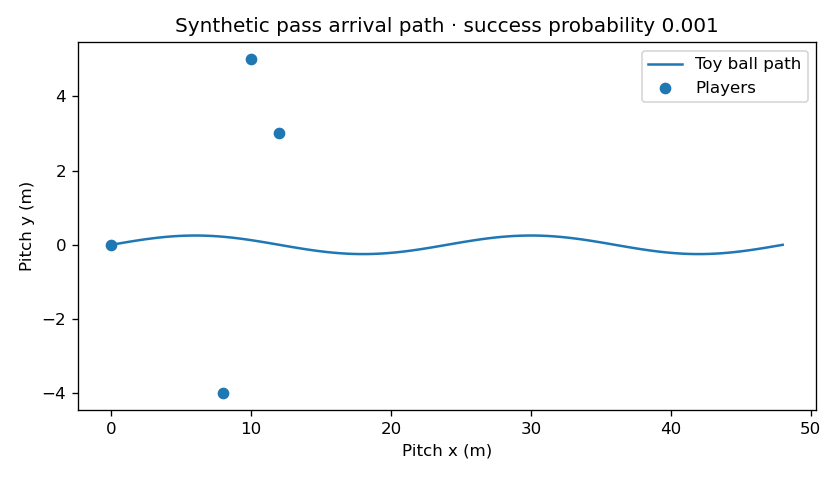

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PRESS.model.solver_pitch_control import integrate_pass_prob
# Synthetic attacking players (carrier, receiver) and defenders.
pos=np.array([[0.,0.],[12.,3.],[8.,-4.],[10.,5.]])
vel=np.zeros_like(pos); idx_attack=np.array([0,1]); carrier_idx=0
t=np.arange(101)*0.04
ball=np.column_stack([12*t, 0.25*np.sin(np.pi*t), 1.2+2.2*np.sin(np.pi*t/4)])
prob=integrate_pass_prob(pos,vel,idx_attack,carrier_idx,ball,lambda_control=4.3,s=0.45,v_max=5.,a_max=5.,dt=0.04,z_max=2.)
fig,ax=plt.subplots(figsize=(7,4)); ax.plot(ball[:,0],ball[:,1],label="Toy ball path"); ax.scatter(pos[:,0],pos[:,1],label="Players"); ax.set(xlabel="Pitch x (m)",ylabel="Pitch y (m)",title=f"Synthetic pass arrival path · success probability {float(prob):.3f}"); ax.legend(); fig.tight_layout()
out=Path("figures/vignette_02_pass_probability.png"); out.parent.mkdir(exist_ok=True); fig.savefig(out,dpi=150); fig.savefig(out.with_suffix(".svg"))

## Use the package on a selected frame

This standalone example initializes one match, selects a team possession and a usable tracking frame, and calls the public API for this task. The match and xT inputs are **synthetic**. Small grids make the example quick and change the model inputs; use the research defaults for analysis. Replace the demo initializer with `PRESS.from_skillcorner(...)` from the [match guide](../../usage.qmd) to use processed local files.

The pitch view below uses the package plotting function and the computed values for frame 5, inside an action interval rather than at its start. It shows the calibrated pass-success field. Candidate fields use a coarse demonstration grid; the synthetic fixture and grid are not a benchmark.


candidate grid: (117, 2)
pass-success range: 0.0019079635385423899 1.0


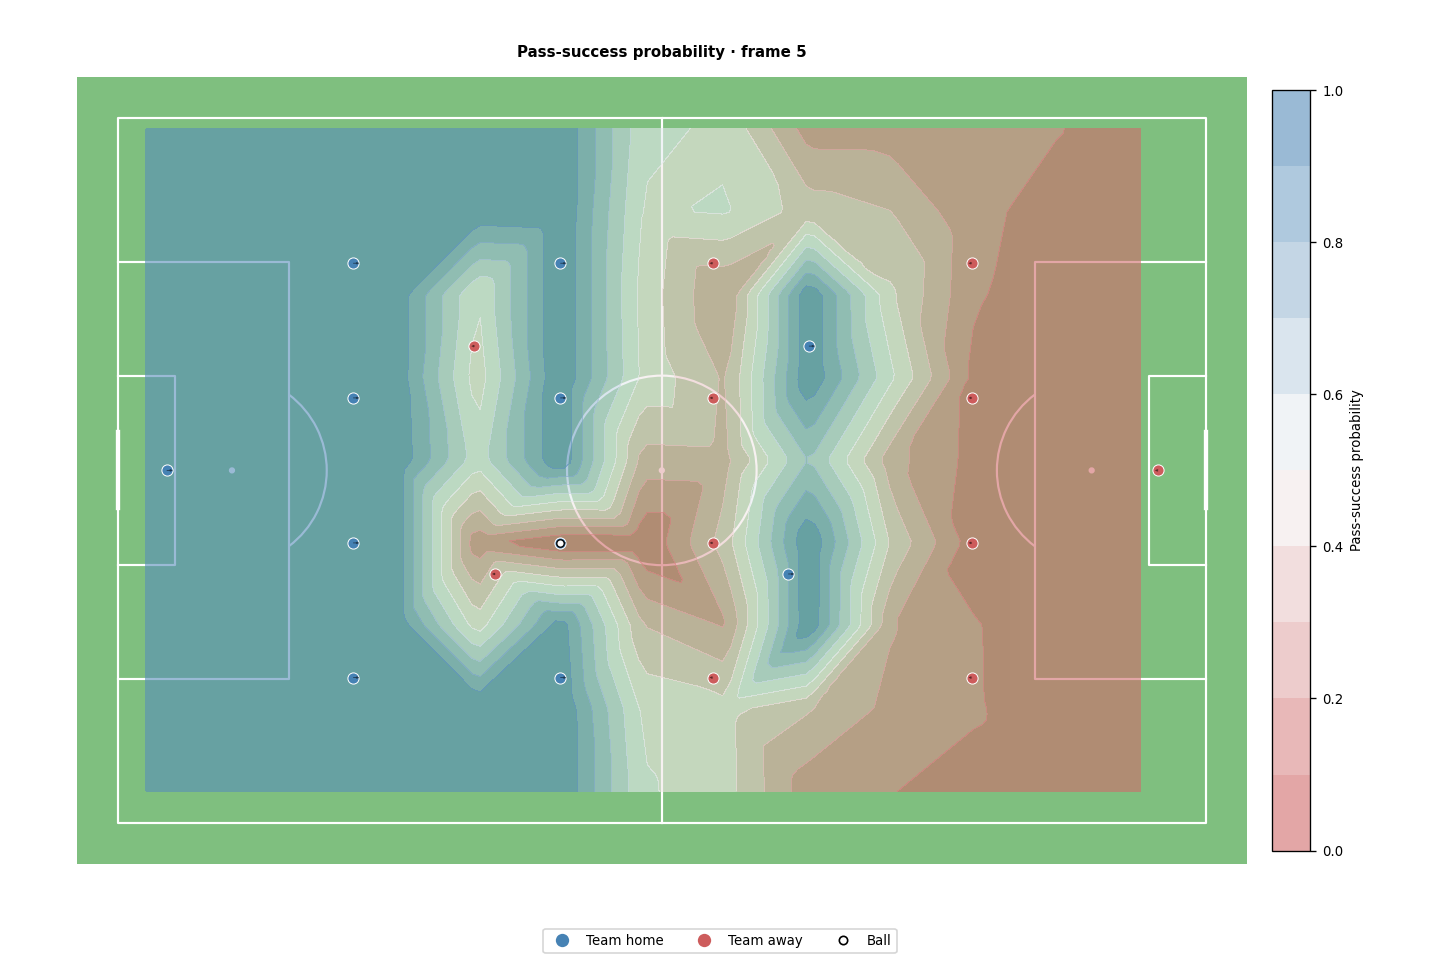

In [5]:
from PRESS import PRESS
from PRESS.datasets import load_demo_match

tracking, possessions, actions, xT_grid = load_demo_match()
model = PRESS(tracking, possessions_data=possessions, actions_data=actions)
possession_id = model.get_possessions().possession_id.iloc[0]
frame_id = int(model.get_frames(possession_id, valid_only=True).frame.iloc[5])
model.compute_ppcf(frame_id, r_max=80, step=8)
result = model.get_ppcf_result(frame_id)
print("candidate grid:", np.asarray(result["grid"]).shape)
print("pass-success range:", float(np.min(result["Pass probability"])), float(np.max(result["Pass probability"])))

from PRESS.visualization import plot_ppcf
plot_ppcf(model, frame_id, field="pass_success")
fig = plt.gcf()
out = Path("figures/vignette_02_pass_pitch.png")
fig.savefig(out, dpi=150); fig.savefig(out.with_suffix(".svg"))
